# Qual melhor prompt para geração de embeddings?
Aqui exploramos como fornecer `preferredLabel`, `altLabels` e `description` da ESCO para o modelo `embeddinggemma`, buscando avaliar qual aproximaria mais competências realmente semelhantes por similaridade de cosseno e qual mais afastaria termos pouco coerentes, seguindo heurística semelhante a da tarefa de clusterização. Assim, buscamos criar representações que aproximassem competências de mesmo domínio, como de tecnologia, e afastassem elas de outras domínios.

Para isso, testamos os seguintes formatos:
- **Skill/Description/Aliases**:  "Skill: {preferredLabel}. Description: {description}. Aliases: {alternativeLabels}"

- **Labels on newlines**: "preferredLabel: {preferredLabel}\n description: {description}\n alternativeLabels: {alternativeLabels}"

- **Portuguese prefixes**: "Competência Técnica: {preferredLabel}. Descrição: {description}. Variações: {alternativeLabels}"

- **Portuguese prefixes with newlines**: "Competência Técnica: {preferredLabel}\n Descrição: {description}\n Variações: {alternativeLabels}"

- **Raw merged spaces**: "{preferredLabel} {description} {alternativeLabels}"

- **Raw merged newlines**: "{preferredLabel}\n {description}\n {alternativeLabels}"
- **Dynamic Type-specific prefix**: 
    - **Portuguese prefixes with newlines**, com ajuste no tipo de competência (Competência Técnica, Comportamental, Conhecimento)

In [1]:
%pip install httpx scikit-learn matplotlib numpy -q


[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import httpx
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import os

OLLAMA_URI = "http://localhost:11434"
EMBEDDING_MODEL = "embeddinggemma"

def get_embedding(text: str) -> np.ndarray:
    """
    Generates embedding for a given text using Ollama.
    Returns a 2D NumPy array (1, embedding_dimension) for compatibility with sklearn's cosine_similarity.
    """
    embed_url = f"{OLLAMA_URI}/api/embed"
    try:
        with httpx.Client(timeout=60.0) as client:
            response = client.post(
                embed_url, json={"model": EMBEDDING_MODEL, "input": text}
            )
            response.raise_for_status() # Raise an exception for bad status codes (4xx or 5xx)
            # Ollama returns a list of embeddings. For a single string input, it returns {"embeddings": [[...]]}
            embedding_list = response.json()["embeddings"][0]
            return np.array(embedding_list).reshape(1, -1)
    except httpx.RequestError as e:
        print(f"Error making request to Ollama. Is your Ollama server running at {OLLAMA_URI}?\nDetails: {e}")
        return np.array([]).reshape(1, -1) # Return empty array to indicate failure
    except httpx.HTTPStatusError as e:
        print(f"Error from Ollama server: {e.response.status_code} - {e.response.text}")
        return np.array([]).reshape(1, -1)
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return np.array([]).reshape(1, -1)

def calculate_cosine_similarity(word1: str, word2: str) -> float:
    """Calculates the cosine similarity between the embeddings of two words."""
    embedding1 = get_embedding(word1)
    embedding2 = get_embedding(word2)

    if embedding1.size == 0 or embedding2.size == 0:
        print("Could not generate embeddings for one or both words. Returning 0.0.")
        return 0.0

    similarity = cosine_similarity(embedding1, embedding2)[0][0]
    return similarity

In [3]:
# Teste para entender o comportamento do modelo de embbeding com multiplas linguas

similarity_score = calculate_cosine_similarity("dog", "cachorro")
print("'dog' e 'cachorro'", similarity_score)

similarity_score = calculate_cosine_similarity("cachorro", "cachorro")
print("'cachorro' e 'cachorro'", similarity_score)

similarity_score = calculate_cosine_similarity("cão", "cachorro")
print("'cão' e 'cachorro'", similarity_score)

'dog' e 'cachorro' 0.8258774536796184
'cachorro' e 'cachorro' 0.9999999999999996
'cão' e 'cachorro' 0.884092671897585


In [4]:
preferredLabel = "definir a estrutura física de uma base de dados"
description = "Especificar a configuração física dos ficheiros de base de dados num determinado suporte. Isto consiste em especificações detalhadas de opções de indexação, tipos de dados e elementos de dados colocados no dicionário de dados."
alternativeLabels = "definir a estrutura física de bases de dados | configurar a estrutura de uma base de dados | configurar bases de dados | definir a estrutura física das bases de dados | definir a estrutura de armazenamento físico de dados"

In [5]:
word_search = "Modelagem Física de Dados"

word_index = f"Skill: {preferredLabel}. Description: {description}. Aliases: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"preferredLabel: {preferredLabel}\n description: {description}\n alternativeLabels: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"Competência Técnica: {preferredLabel}. Descrição: {description}. Variações: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"Competência Técnica: {preferredLabel}\n Descrição: {description}\n Variações: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"{preferredLabel} {description} {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"{preferredLabel}\n {description}\n {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

The cosine similarity is: 0.3713
The cosine similarity is: 0.3813
The cosine similarity is: 0.3304
The cosine similarity is: 0.3486
The cosine similarity is: 0.3590
The cosine similarity is: 0.3694


In [9]:
word_index = f"Competência Técnica: {preferredLabel}. Descrição: {description}. Variações: {alternativeLabels}"

word_search = "Competência Técnica: Modelagem Física de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_search = "Competência Técnica: Design de Banco de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_search = "Competência Técnica: Otimização e Indexação de Bancos de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

The cosine similarity is: 0.4386
The cosine similarity is: 0.5044
The cosine similarity is: 0.4534


In [ ]:
word_index = f"Competência Técnica: {preferredLabel}"

word_search = "Competência Técnica: Modelagem Física de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_search = "Competência Técnica: Design de Banco de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_search = "Competência Técnica: Otimização e Indexação de Bancos de Dados"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

The cosine similarity is: 0.6383
The cosine similarity is: 0.7050
The cosine similarity is: 0.5812


In [12]:
# Get input from the user
word1 = input("Enter the first word: ")
word2 = input("Enter the second word: ")

# Calculate and display the similarity
similarity_score = calculate_cosine_similarity(word1, word2)
print(f"The cosine similarity between '{word1}' and '{word2}' is: {similarity_score:.4f}")

The cosine similarity between 'teste' and 'teste' is: 1.0000


## Testing best embbeding format

In [29]:
import csv
import random
import httpx
import json
import numpy as np
import os

# Configuration
CSV_PATH = "../data/esco_dataset/digitalSkillsCollection_pt.csv"
CHAT_MODEL = "gemma3:1b"
N_SAMPLES = 100  # Number of skills to sample and test
DB_PATH = "embedding_issues_ptBR_ptPT.json"

# Load and filter skills
skills_pool = []
try:
    with open(CSV_PATH, mode='r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            raw_type = row["skillType"]
            reuse_level = row["reuseLevel"]

            if raw_type == "knowledge":
                mapped_type = "knowledge"
            elif raw_type == "skill/competence":
                if not reuse_level:
                    continue

                if reuse_level == "transversal":
                    mapped_type = "soft"
                elif reuse_level in [
                    "sector-specific",
                    "occupation-specific",
                    "cross-sector"
                ]:
                    mapped_type = "hard"
                else:
                    continue
            else:
                continue

            row["mappedType"] = mapped_type
            skills_pool.append(row)
except Exception:
    pass

if len(skills_pool) < N_SAMPLES:
    N_SAMPLES = len(skills_pool)

# Select random sample
sampled_skills = random.sample(skills_pool, N_SAMPLES)

# Load existing database
database = []
if os.path.exists(DB_PATH):
    try:
        with open(DB_PATH, "r", encoding="utf-8") as db_f:
            database = json.load(db_f)
    except Exception:
        pass

# Helper function to get synonyms from Gemma 3
def get_synonyms_from_gemma(preferredLabel, description, altLabels, model=CHAT_MODEL):
    prompt = f"""Uma das Competências ou Conhecimentos definidos na ESCO é:

preferredLabel = \"{preferredLabel}\"
description = \"{description}\"
alternativeLabels = \"{altLabels}\"

Qual seria um sinônimo para \"{preferredLabel}\" em uma linguagem do dia a dia que apareceria em um currículo por exemplo?

Retorne APENAS uma lista JSON contendo entre 3 e 5 sinônimos/frases curtas equivalentes em português.
Exemplo de saída esperada:
[\"Modelagem Física de Dados\", \"Design de Banco de Dados\", \"Otimização e Indexação de Bancos de Dados\"]
"""
    try:
        with httpx.Client(timeout=60.0) as client:
            response = client.post(
                f"{OLLAMA_URI}/api/chat",
                json={
                    "model": model,
                    "messages": [{"role": "user", "content": prompt}],
                    "stream": False,
                    "format": "json",
                    "options": {
                        "num_batch": "1024"
                    }
                }
            )
            response.raise_for_status()
            content = response.json()["message"]["content"]
            
            data = json.loads(content)
            if isinstance(data, list):
                return data
            elif isinstance(data, dict):
                for key, val in data.items():
                    if isinstance(val, list):
                        return val
            return [preferredLabel]
    except Exception:
        return [preferredLabel]

# Formats to test
formats = {
    "Skill/Description/Aliases": lambda label, desc, alts, mtype: f"Skill: {label}. Description: {desc}. Aliases: {alts}",
    "labels on newlines": lambda label, desc, alts, mtype: f"preferredLabel: {label}\n description: {desc}\n alternativeLabels: {alts}",
    "Portuguese prefixes": lambda label, desc, alts, mtype: f"Competência: {label}. Descrição: {desc}. Variações: {alts}",
    "Portuguese prefixes with newlines": lambda label, desc, alts, mtype: f"Competência: {label}\n Descrição: {desc}\n Variações: {alts}",
    "Raw merged spaces": lambda label, desc, alts, mtype: f"{label} {desc} {alts}",
    "Raw merged newlines": lambda label, desc, alts, mtype: f"{label}\n {desc}\n {alts}",
    "Dynamic Type-specific prefix": lambda label, desc, alts, mtype: (
        f"Conhecimento: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "knowledge"
        else f"Competência Comportamental: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "soft"
        else f"Competência Técnica: {label}\n Descrição: {desc}\n Variações: {alts}"
    )
}

# Run the test
for skill in sampled_skills:
    label = skill["preferredLabel"]
    desc = skill["description"]
    alts = skill["altLabels"] if skill["altLabels"] else ""
    mtype = skill["mappedType"]
    concept_uri = skill.get("conceptUri", "")
    
    # Get synonyms from Gemma 3
    synonyms = get_synonyms_from_gemma(label, desc, alts)
    
    for synonym in synonyms:
        record = {
            "conceptUri": concept_uri,
            "preferredLabel": label,
            "mappedType": mtype,
            "synonym": synonym,
            "similarities": {}
        }
        
        for name, format_fn in formats.items():
            word_index = format_fn(label, desc, alts, mtype)
            similarity = calculate_cosine_similarity(word_index, synonym)
            record["similarities"][name] = float(similarity)
            
        database.append(record)

try:
    with open(DB_PATH, "w", encoding="utf-8") as db_f:
        json.dump(database, db_f, indent=2, ensure_ascii=False)
except Exception:
        pass

KeyboardInterrupt: 

Analyzing 129 total test records...

                        OVERALL FORMAT RANKING                        
  1. Raw merged newlines                           | Average Similarity: 0.66910
  2. Raw merged spaces                             | Average Similarity: 0.65557
  3. labels on newlines                            | Average Similarity: 0.64430
  4. Skill/Description/Aliases                     | Average Similarity: 0.62890
  5. Dynamic Type-specific prefix                  | Average Similarity: 0.61878
  6. Portuguese prefixes with newlines             | Average Similarity: 0.61468
  7. Portuguese prefixes                           | Average Similarity: 0.60101

                  RANKING FOR SKILL TYPE: KNOWLEDGE                   
  1. Raw merged newlines                           | Average Similarity: 0.62305
  2. Raw merged spaces                             | Average Similarity: 0.60573
  3. labels on newlines                            | Average Similarity: 0.59587
  4. Dynam

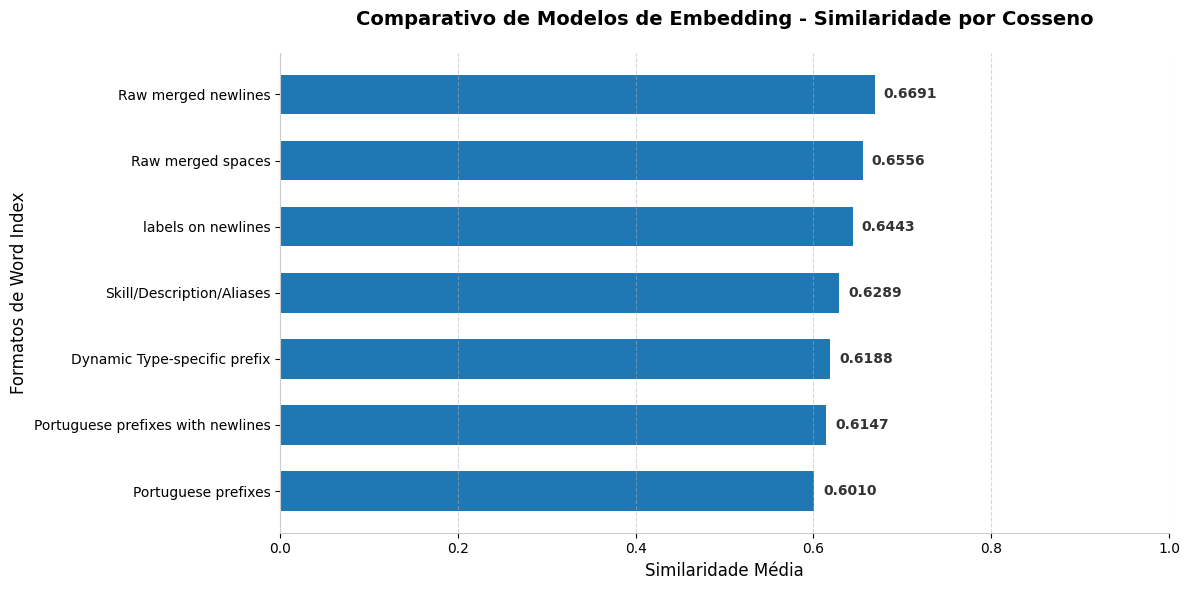

In [22]:
import json
import numpy as np
import os

DB_PATH = "embedding_issues_ptBR_ptPT.json"

if not os.path.exists(DB_PATH):
    print(f"Error: Database file '{DB_PATH}' not found. Please run the test cell first.")
else:
    with open(DB_PATH, "r", encoding="utf-8") as f:
        data = json.load(f)
        
    print(f"Analyzing {len(data)} total test records...\n")
    
    # Group records by type
    by_type = {}
    overall_scores = {}
    
    for item in data:
        mtype = item["mappedType"]
        if mtype not in by_type:
            by_type[mtype] = {}
            
        for fmt, val in item["similarities"].items():
            if fmt not in overall_scores:
                overall_scores[fmt] = []
            overall_scores[fmt].append(val)
            
            if fmt not in by_type[mtype]:
                by_type[mtype][fmt] = []
            by_type[mtype][fmt].append(val)
            
    # Calculate overall averages
    overall_avgs = {fmt: np.mean(scores) for fmt, scores in overall_scores.items()}
    sorted_overall = sorted(overall_avgs.items(), key=lambda x: x[1], reverse=True)
    
    print("=" * 70)
    print(f"{'OVERALL FORMAT RANKING':^70}")
    print("=" * 70)
    for rank, (name, score) in enumerate(sorted_overall, 1):
        print(f" {rank:2d}. {name:<45} | Average Similarity: {score:.5f}")
    print("=" * 70)
    
    # Calculate by type
    for mtype, formats_dict in by_type.items():
        type_avgs = {fmt: np.mean(scores) for fmt, scores in formats_dict.items()}
        sorted_type = sorted(type_avgs.items(), key=lambda x: x[1], reverse=True)
        
        print("\n" + "=" * 70)
        print(f"{f'RANKING FOR SKILL TYPE: {mtype.upper()}':^70}")
        print("=" * 70)
        for rank, (name, score) in enumerate(sorted_type, 1):
            print(f" {rank:2d}. {name:<45} | Average Similarity: {score:.5f}")
        print("=" * 70)

    # Optional: Try to plot using matplotlib if available
    try:
        import matplotlib.pyplot as plt
        
        formats_names = [x[0] for x in sorted_overall]
        averages = [x[1] for x in sorted_overall]
        
        plt.figure(figsize=(12, 6))
        bars = plt.barh(formats_names, averages, color='#1f77b4', edgecolor='none', height=0.6)
        
        # Style
        plt.title('Comparativo de Modelos de Embedding - Similaridade por Cosseno', fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Similaridade Média', fontsize=12)
        plt.ylabel('Formatos de Word Index', fontsize=12)
        plt.xlim(0, 1.0)
        plt.gca().invert_yaxis()  # Best on top
        
        # Grid and borders
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.gca().spines['left'].set_color('#cccccc')
        plt.gca().spines['bottom'].set_color('#cccccc')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        
        # Add values inside/outside the bars
        for bar in bars:
            width = bar.get_width()
            plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
                     va='center', ha='left', fontsize=10, fontweight='semibold', color='#333333')
            
        plt.tight_layout()
        plt.show()
    except ImportError:
        print("\nNote: matplotlib not installed. Install it with '%pip install matplotlib' to see the chart.")

## Teste de diferenciação

- Skill Não tecnologia = skills_pt.csv - digitalSkillsCollection_pt.csv
- Calcular a média de similaridade das skills de tecnologia (digitalSkillsCollection_pt.csv) - FEITO
- Calcular a média de similaridade das skills não tecnologia 

- Conclusão: Melhor modelo é:
    - Maximiza a média de similaridade das skills de tecnologia
    - Minimiza a média de similaridade das skills não tecnologia 

In [6]:
preferredLabel = "gerir grupos de turistas"
description = "Monitorizar e guiar turistas para assegurar uma dinâmica de grupo positiva e abordar eventuais conflitos e preocupações."
alternativeLabels = "gerir grupos turísticos | guiar e coordenar grupos de turistas | coordenar grupos turísticos | coordenar e guiar grupos de turistas"

In [7]:
word_search = "Competência Comportamental: retórica"

word_index = f"Skill: {preferredLabel}. Description: {description}. Aliases: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"preferredLabel: {preferredLabel}\n description: {description}\n alternativeLabels: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"Competência Técnica: {preferredLabel}. Descrição: {description}. Variações: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"Competência Técnica: {preferredLabel}\n Descrição: {description}\n Variações: {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"{preferredLabel} {description} {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

word_index = f"{preferredLabel}\n {description}\n {alternativeLabels}"
similarity_score = calculate_cosine_similarity(word_index, word_search)
print(f"The cosine similarity is: {similarity_score:.4f}")

The cosine similarity is: 0.3209
The cosine similarity is: 0.3104
The cosine similarity is: 0.3615
The cosine similarity is: 0.3797
The cosine similarity is: 0.2605
The cosine similarity is: 0.2654


## Extraindo habilidades de não tecnologia de skills_pt.csv

In [12]:
import csv
import pandas as pd

SKILLS_PT_PATH = "../data/esco_dataset/skills_pt.csv"
DIGITAL_SKILLS_PT_PATH = "../data/esco_dataset/digitalSkillsCollection_pt.csv"
OUTPUT_PATH = "no_digital_skills_pt.csv"

def parse_skills(filepath):
    skills = []
    with open(filepath, mode='r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            raw_type = row["skillType"]
            reuse_level = row["reuseLevel"]

            if raw_type == "knowledge":
                mapped_type = "knowledge"
            elif raw_type == "skill/competence":
                if not reuse_level:
                    continue
                if reuse_level == "transversal":
                    mapped_type = "soft"
                elif reuse_level in ["sector-specific", "occupation-specific", "cross-sector"]:
                    mapped_type = "hard"
                else:
                    continue
            else:
                continue

            skills.append({
                "uri": row["conceptUri"],
                "skill_type": mapped_type,
                "preferred_label": row["preferredLabel"],
                "alt_labels": row["altLabels"],
                "description": row["description"],
            })
    return skills

all_skills = parse_skills(SKILLS_PT_PATH)
digital_skills = parse_skills(DIGITAL_SKILLS_PT_PATH)

digital_uris = {s["uri"] for s in digital_skills}

non_digital_skills = [s for s in all_skills if s["uri"] not in digital_uris]

df = pd.DataFrame(non_digital_skills)
df.to_csv(OUTPUT_PATH, index=False, encoding='utf-8')

print(f"Total skills_pt:          {len(all_skills)}")
print(f"Total digital skills:     {len(digital_skills)}")
print(f"Total non-digital skills: {len(non_digital_skills)}")
print(f"Arquivo salvo em: {OUTPUT_PATH}")
df.head()


Total skills_pt:          13955
Total digital skills:     1284
Total non-digital skills: 12670
Arquivo salvo em: no_digital_skills_pt.csv


,uri,skill_type,preferred_label,alt_labels,description
0,http://data.europa.eu/esco/skill/0005c151-5b5a...,hard,gerir músicos,,Atribuir e gerir as tarefas do pessoal em área...
1,http://data.europa.eu/esco/skill/00064735-8fad...,hard,supervisionar procedimentos correcionais,,Supervisionar as operações de uma instalação c...
2,http://data.europa.eu/esco/skill/000709ed-2be5...,hard,aplicar práticas anti-repressivas,,"Identificar a repressão em sociedades, economi..."
3,http://data.europa.eu/esco/skill/0007bdc2-dd15...,hard,controlar a conformidade dos veículos ferroviá...,,"Inspecionar o material circulante, componentes..."
4,http://data.europa.eu/esco/skill/00090cc1-1f27...,hard,identificar os serviços disponíveis,,Identificar os diferentes serviços disponíveis...


## Testando geração dos embeddings de non_digital_skills_pt.csv

In [9]:
import random

# Configuration
CSV_PATH_NON_DIGITAL = "../data/esco_dataset/no_digital_skills_pt.csv"
CHAT_MODEL = "gemma3:1b"
N_SAMPLES = 100  # Number of skills to sample and test
DB_PATH = "embedding_issues_non_digital_skills_ptBR_ptPT.json"

# Load skills
skills_pool = []
try:
    with open(CSV_PATH_NON_DIGITAL, mode='r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            skills_pool.append({
                "conceptUri": row["uri"],
                "preferredLabel": row["preferred_label"],
                "altLabels": row["alt_labels"],
                "description": row["description"],
                "mappedType": row["skill_type"],
            })
except Exception as e:
    print(f"Erro ao carregar CSV: {e}")

if len(skills_pool) < N_SAMPLES:
    N_SAMPLES = len(skills_pool)

print(f"Skills carregadas: {len(skills_pool)}, amostras: {N_SAMPLES}")

# Select random sample
sampled_skills = random.sample(skills_pool, N_SAMPLES)

# Load existing database
database = []
if os.path.exists(DB_PATH):
    try:
        with open(DB_PATH, "r", encoding="utf-8") as db_f:
            database = json.load(db_f)
    except Exception:
        pass

# Helper function to get synonyms from Gemma 3
def get_synonyms_from_gemma(preferredLabel, description, altLabels, model=CHAT_MODEL):
    prompt = f"""Uma das Competências ou Conhecimentos definidos na ESCO é:

preferredLabel = \"{preferredLabel}\"
description = \"{description}\"
alternativeLabels = \"{altLabels}\"

Qual seria um sinônimo para \"{preferredLabel}\" em uma linguagem do dia a dia que apareceria em um currículo por exemplo?

Retorne APENAS uma lista JSON contendo entre 3 e 5 sinônimos/frases curtas equivalentes em português.
Exemplo de saída esperada:
[\"Modelagem Física de Dados\", \"Design de Banco de Dados\", \"Otimização e Indexação de Bancos de Dados\"]
"""
    try:
        with httpx.Client(timeout=60.0) as client:
            response = client.post(
                f"{OLLAMA_URI}/api/chat",
                json={
                    "model": model,
                    "messages": [{"role": "user", "content": prompt}],
                    "stream": False,
                    "format": "json",
                    "options": {
                        "num_batch": "1024"
                    }
                }
            )
            response.raise_for_status()
            content = response.json()["message"]["content"]

            data = json.loads(content)
            if isinstance(data, list):
                return data
            elif isinstance(data, dict):
                for key, val in data.items():
                    if isinstance(val, list):
                        return val
            return [preferredLabel]
    except Exception:
        return [preferredLabel]

# Formats to test
formats = {
    "Skill/Description/Aliases": lambda label, desc, alts, mtype: f"Skill: {label}. Description: {desc}. Aliases: {alts}",
    "labels on newlines": lambda label, desc, alts, mtype: f"preferredLabel: {label}\n description: {desc}\n alternativeLabels: {alts}",
    "Portuguese prefixes": lambda label, desc, alts, mtype: f"Competência: {label}. Descrição: {desc}. Variações: {alts}",
    "Portuguese prefixes with newlines": lambda label, desc, alts, mtype: f"Competência: {label}\n Descrição: {desc}\n Variações: {alts}",
    "Raw merged spaces": lambda label, desc, alts, mtype: f"{label} {desc} {alts}",
    "Raw merged newlines": lambda label, desc, alts, mtype: f"{label}\n {desc}\n {alts}",
    "Dynamic Type-specific prefix": lambda label, desc, alts, mtype: (
        f"Conhecimento: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "knowledge"
        else f"Competência Comportamental: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "soft"
        else f"Competência Técnica: {label}\n Descrição: {desc}\n Variações: {alts}"
    )
}

# Run the test
for skill in sampled_skills:
    label = skill["preferredLabel"]
    desc = skill["description"]
    alts = skill["altLabels"] if skill["altLabels"] else ""
    mtype = skill["mappedType"]
    concept_uri = skill["conceptUri"]

    synonyms = get_synonyms_from_gemma(label, desc, alts)

    for synonym in synonyms:
        record = {
            "conceptUri": concept_uri,
            "preferredLabel": label,
            "mappedType": mtype,
            "synonym": synonym,
            "similarities": {}
        }

        for name, format_fn in formats.items():
            word_index = format_fn(label, desc, alts, mtype)
            similarity = calculate_cosine_similarity(word_index, synonym)
            record["similarities"][name] = float(similarity)

        database.append(record)

try:
    with open(DB_PATH, "w", encoding="utf-8") as db_f:
        json.dump(database, db_f, indent=2, ensure_ascii=False)
except Exception as e:
    print(f"Erro ao salvar: {e}")

Erro ao carregar CSV: name 'csv' is not defined
Skills carregadas: 0, amostras: 0
Erro ao salvar: name 'json' is not defined


Analyzing 100 total test records...

                        OVERALL FORMAT RANKING                        
  1. Raw merged newlines                           | Average Similarity: 0.73863
  2. Raw merged spaces                             | Average Similarity: 0.72727
  3. labels on newlines                            | Average Similarity: 0.70846
  4. Skill/Description/Aliases                     | Average Similarity: 0.69277
  5. Portuguese prefixes with newlines             | Average Similarity: 0.67601
  6. Dynamic Type-specific prefix                  | Average Similarity: 0.67336
  7. Portuguese prefixes                           | Average Similarity: 0.66253

                  RANKING FOR SKILL TYPE: KNOWLEDGE                   
  1. Raw merged newlines                           | Average Similarity: 0.67187
  2. Raw merged spaces                             | Average Similarity: 0.65263
  3. labels on newlines                            | Average Similarity: 0.63461
  4. Dynam

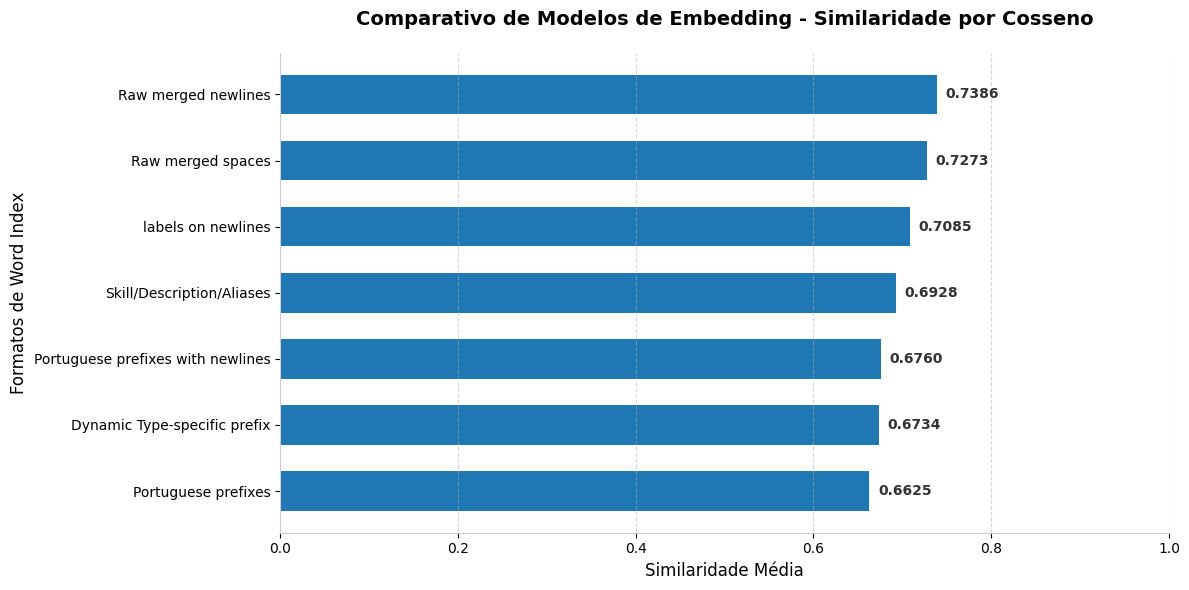

In [15]:
DB_PATH = "embedding_issues_non_digital_skills_ptBR_ptPT.json"

if not os.path.exists(DB_PATH):
    print(f"Error: Database file '{DB_PATH}' not found. Please run the test cell first.")
else:
    with open(DB_PATH, "r", encoding="utf-8") as f:
        data = json.load(f)
        
    print(f"Analyzing {len(data)} total test records...\n")
    
    # Group records by type
    by_type = {}
    overall_scores = {}
    
    for item in data:
        mtype = item["mappedType"]
        if mtype not in by_type:
            by_type[mtype] = {}
            
        for fmt, val in item["similarities"].items():
            if fmt not in overall_scores:
                overall_scores[fmt] = []
            overall_scores[fmt].append(val)
            
            if fmt not in by_type[mtype]:
                by_type[mtype][fmt] = []
            by_type[mtype][fmt].append(val)
            
    # Calculate overall averages
    overall_avgs = {fmt: np.mean(scores) for fmt, scores in overall_scores.items()}
    sorted_overall = sorted(overall_avgs.items(), key=lambda x: x[1], reverse=True)
    
    print("=" * 70)
    print(f"{'OVERALL FORMAT RANKING':^70}")
    print("=" * 70)
    for rank, (name, score) in enumerate(sorted_overall, 1):
        print(f" {rank:2d}. {name:<45} | Average Similarity: {score:.5f}")
    print("=" * 70)
    
    # Calculate by type
    for mtype, formats_dict in by_type.items():
        type_avgs = {fmt: np.mean(scores) for fmt, scores in formats_dict.items()}
        sorted_type = sorted(type_avgs.items(), key=lambda x: x[1], reverse=True)
        
        print("\n" + "=" * 70)
        print(f"{f'RANKING FOR SKILL TYPE: {mtype.upper()}':^70}")
        print("=" * 70)
        for rank, (name, score) in enumerate(sorted_type, 1):
            print(f" {rank:2d}. {name:<45} | Average Similarity: {score:.5f}")
        print("=" * 70)

    # Optional: Try to plot using matplotlib if available
    try:
        import matplotlib.pyplot as plt
        
        formats_names = [x[0] for x in sorted_overall]
        averages = [x[1] for x in sorted_overall]
        
        plt.figure(figsize=(12, 6))
        bars = plt.barh(formats_names, averages, color='#1f77b4', edgecolor='none', height=0.6)
        
        # Style
        plt.title('Comparativo de Modelos de Embedding - Similaridade por Cosseno', fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Similaridade Média', fontsize=12)
        plt.ylabel('Formatos de Word Index', fontsize=12)
        plt.xlim(0, 1.0)
        plt.gca().invert_yaxis()  # Best on top
        
        # Grid and borders
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.gca().spines['left'].set_color('#cccccc')
        plt.gca().spines['bottom'].set_color('#cccccc')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        
        # Add values inside/outside the bars
        for bar in bars:
            width = bar.get_width()
            plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
                     va='center', ha='left', fontsize=10, fontweight='semibold', color='#333333')
            
        plt.tight_layout()
        plt.show()
    except ImportError:
        print("\nNote: matplotlib not installed. Install it with '%pip install matplotlib' to see the chart.")

## Realizando teste para provar maior similaridade de termos de mesmo domínio

In [10]:
import csv
import json
import random
import numpy as np
import httpx
from sklearn.metrics.pairwise import cosine_similarity

# --- Âncoras de domínio ---
TECH_ANCHORS = [
    "programação",
    "desenvolvimento de software",
    "banco de dados",
    "redes de computadores",
    "segurança da informação",
    "inteligência artificial",
    "análise de dados",
    "infraestrutura de TI",
]

NON_TECH_ANCHORS = [
    "culinária",
    "agricultura",
    "turismo",
    "enfermagem",
    "gestão de pessoas",
    "construção civil",
    "direito",
    "contabilidade",
]

N_SAMPLES = 100
DIGITAL_CSV = "../data/esco_dataset/digitalSkillsCollection_pt.csv"
NON_DIGITAL_CSV = "../data/esco_dataset/no_digital_skills_pt.csv"
DB_PATH = "domain_discrimination_by_format.json"

# --- Formatos ---
formats = {
    "Raw merged newlines":               lambda label, desc, alts, mtype: f"{label}\n {desc}\n {alts}",
    "Raw merged spaces":                 lambda label, desc, alts, mtype: f"{label} {desc} {alts}",
    "labels on newlines":                lambda label, desc, alts, mtype: f"preferredLabel: {label}\n description: {desc}\n alternativeLabels: {alts}",
    "Skill/Description/Aliases":         lambda label, desc, alts, mtype: f"Skill: {label}. Description: {desc}. Aliases: {alts}",
    "Portuguese prefixes with newlines": lambda label, desc, alts, mtype: f"Competência: {label}\n Descrição: {desc}\n Variações: {alts}",
    "Portuguese prefixes":               lambda label, desc, alts, mtype: f"Competência: {label}. Descrição: {desc}. Variações: {alts}",
    "Dynamic Type-specific prefix":      lambda label, desc, alts, mtype: (
        f"Conhecimento: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "knowledge"
        else f"Competência Comportamental: {label}\n Descrição: {desc}\n Variações: {alts}" if mtype == "soft"
        else f"Competência Técnica: {label}\n Descrição: {desc}\n Variações: {alts}"
    ),
}

# --- Carrega skills ---
def load_digital_skills(filepath, n):
    skills = []
    with open(filepath, mode='r', encoding='utf-8') as f:
        for row in csv.DictReader(f):
            raw_type = row["skillType"]
            reuse_level = row["reuseLevel"]
            if raw_type == "knowledge":
                mtype = "knowledge"
            elif raw_type == "skill/competence" and reuse_level:
                if reuse_level == "transversal":
                    mtype = "soft"
                elif reuse_level in ["sector-specific", "occupation-specific", "cross-sector"]:
                    mtype = "hard"
                else:
                    continue
            else:
                continue
            skills.append({
                "uri": row["conceptUri"],
                "preferred_label": row["preferredLabel"],
                "alt_labels": row.get("altLabels", ""),
                "description": row.get("description", ""),
                "skill_type": mtype,
            })
    return random.sample(skills, min(n, len(skills)))

def load_non_digital_skills(filepath, n):
    skills = []
    with open(filepath, mode='r', encoding='utf-8') as f:
        for row in csv.DictReader(f):
            skills.append({
                "uri": row["uri"],
                "preferred_label": row["preferred_label"],
                "alt_labels": row.get("alt_labels", ""),
                "description": row.get("description", ""),
                "skill_type": row["skill_type"],
            })
    return random.sample(skills, min(n, len(skills)))

def avg_similarity_to_group(skill_embedding, anchor_embeddings):
    scores = [cosine_similarity(skill_embedding, a)[0][0] for a in anchor_embeddings]
    return float(np.mean(scores))

# --- Pré-computa embeddings das âncoras (uma vez por formato seria redundante — âncoras são fixas) ---
print("Gerando embeddings das âncoras...")
tech_anchor_embeddings = [get_embedding(t) for t in TECH_ANCHORS]
non_tech_anchor_embeddings = [get_embedding(t) for t in NON_TECH_ANCHORS]

# --- Carrega amostras ---
digital_skills = load_digital_skills(DIGITAL_CSV, N_SAMPLES)
non_digital_skills = load_non_digital_skills(NON_DIGITAL_CSV, N_SAMPLES)

# --- Estrutura de resultados por formato ---
results = {fmt: {"digital": [], "non_digital": []} for fmt in formats}

# --- Processa cada grupo e formato ---
for group_name, skills in [("digital", digital_skills), ("non_digital", non_digital_skills)]:
    print(f"\nProcessando {group_name} ({len(skills)} skills)...")
    for skill in skills:
        label = skill["preferred_label"]
        desc  = skill["description"]
        alts  = skill["alt_labels"] or ""
        mtype = skill["skill_type"]

        for fmt_name, fmt_fn in formats.items():
            emb = get_embedding(fmt_fn(label, desc, alts, mtype))
            if emb.size == 0:
                continue

            sim_tech     = avg_similarity_to_group(emb, tech_anchor_embeddings)
            sim_non_tech = avg_similarity_to_group(emb, non_tech_anchor_embeddings)

            results[fmt_name][group_name].append({
                "uri":           skill["uri"],
                "preferred_label": label,
                "skill_type":    mtype,
                "sim_tech":      sim_tech,
                "sim_non_tech":  sim_non_tech,
                "delta":         sim_tech - sim_non_tech,
            })

with open(DB_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

# --- Tabela comparativa ---
print(f"\n{'Formato':<40} {'Δ Digital':>10} {'Δ Non-dig':>10} {'Separação':>11}")
print("=" * 75)

ranking = []
for fmt_name, groups in results.items():
    dig     = groups["digital"]
    non_dig = groups["non_digital"]

    delta_dig     = np.mean([r["delta"] for r in dig])
    delta_non_dig = np.mean([r["delta"] for r in non_dig])
    # Separação = quão diferente é o comportamento entre os dois grupos
    separation = delta_dig - delta_non_dig
    ranking.append((fmt_name, delta_dig, delta_non_dig, separation))

for fmt_name, d_dig, d_non, sep in sorted(ranking, key=lambda x: x[3], reverse=True):
    ok_dig  = "✓" if d_dig > 0 else "✗"
    ok_non  = "✓" if d_non < 0 else "✗"
    print(f"{fmt_name:<40} {ok_dig}{d_dig:>+8.5f}  {ok_non}{d_non:>+8.5f}  {sep:>+10.5f}")

Gerando embeddings das âncoras...

Processando digital (100 skills)...

Processando non_digital (100 skills)...

Formato                                   Δ Digital  Δ Non-dig   Separação
Raw merged spaces                        ✓+0.07006  ✓-0.00409    +0.07416
Raw merged newlines                      ✓+0.06972  ✓-0.00379    +0.07351
Dynamic Type-specific prefix             ✓+0.04990  ✓-0.02150    +0.07140
Portuguese prefixes                      ✓+0.05396  ✓-0.01702    +0.07099
Portuguese prefixes with newlines        ✓+0.05237  ✓-0.01707    +0.06944
Skill/Description/Aliases                ✓+0.05520  ✓-0.01307    +0.06826
labels on newlines                       ✓+0.05317  ✓-0.01111    +0.06428


## Conclusão e Veredito

Após várias baterias de testes, optamos por usar o formato **Raw merged newlines**: "{preferredLabel}\n{description}\n{alternativeLabels}".